In [1]:
from utils import get_hdf5_files, get_filename, get_continuous_behaviors, get_discrete_states, get_eigenworms, get_kymograph, get_neuronal_traces

import os
import math
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
path = f'{os.getcwd()}/../data/{os.path.basename(os.getcwd())}/exported_data_/'
hdf5files = get_hdf5_files(path)
filenames = [get_filename(file) for file in hdf5files]
continuous_behaviors = [get_continuous_behaviors(file) for file in hdf5files]
discrete_states = [get_discrete_states(file) for file in hdf5files]
eigenworms = [get_eigenworms(file) for file in hdf5files]
kymographs = [get_kymograph(file) for file in hdf5files]
traces = [get_neuronal_traces(file) for file in hdf5files]

0.6495618733019867


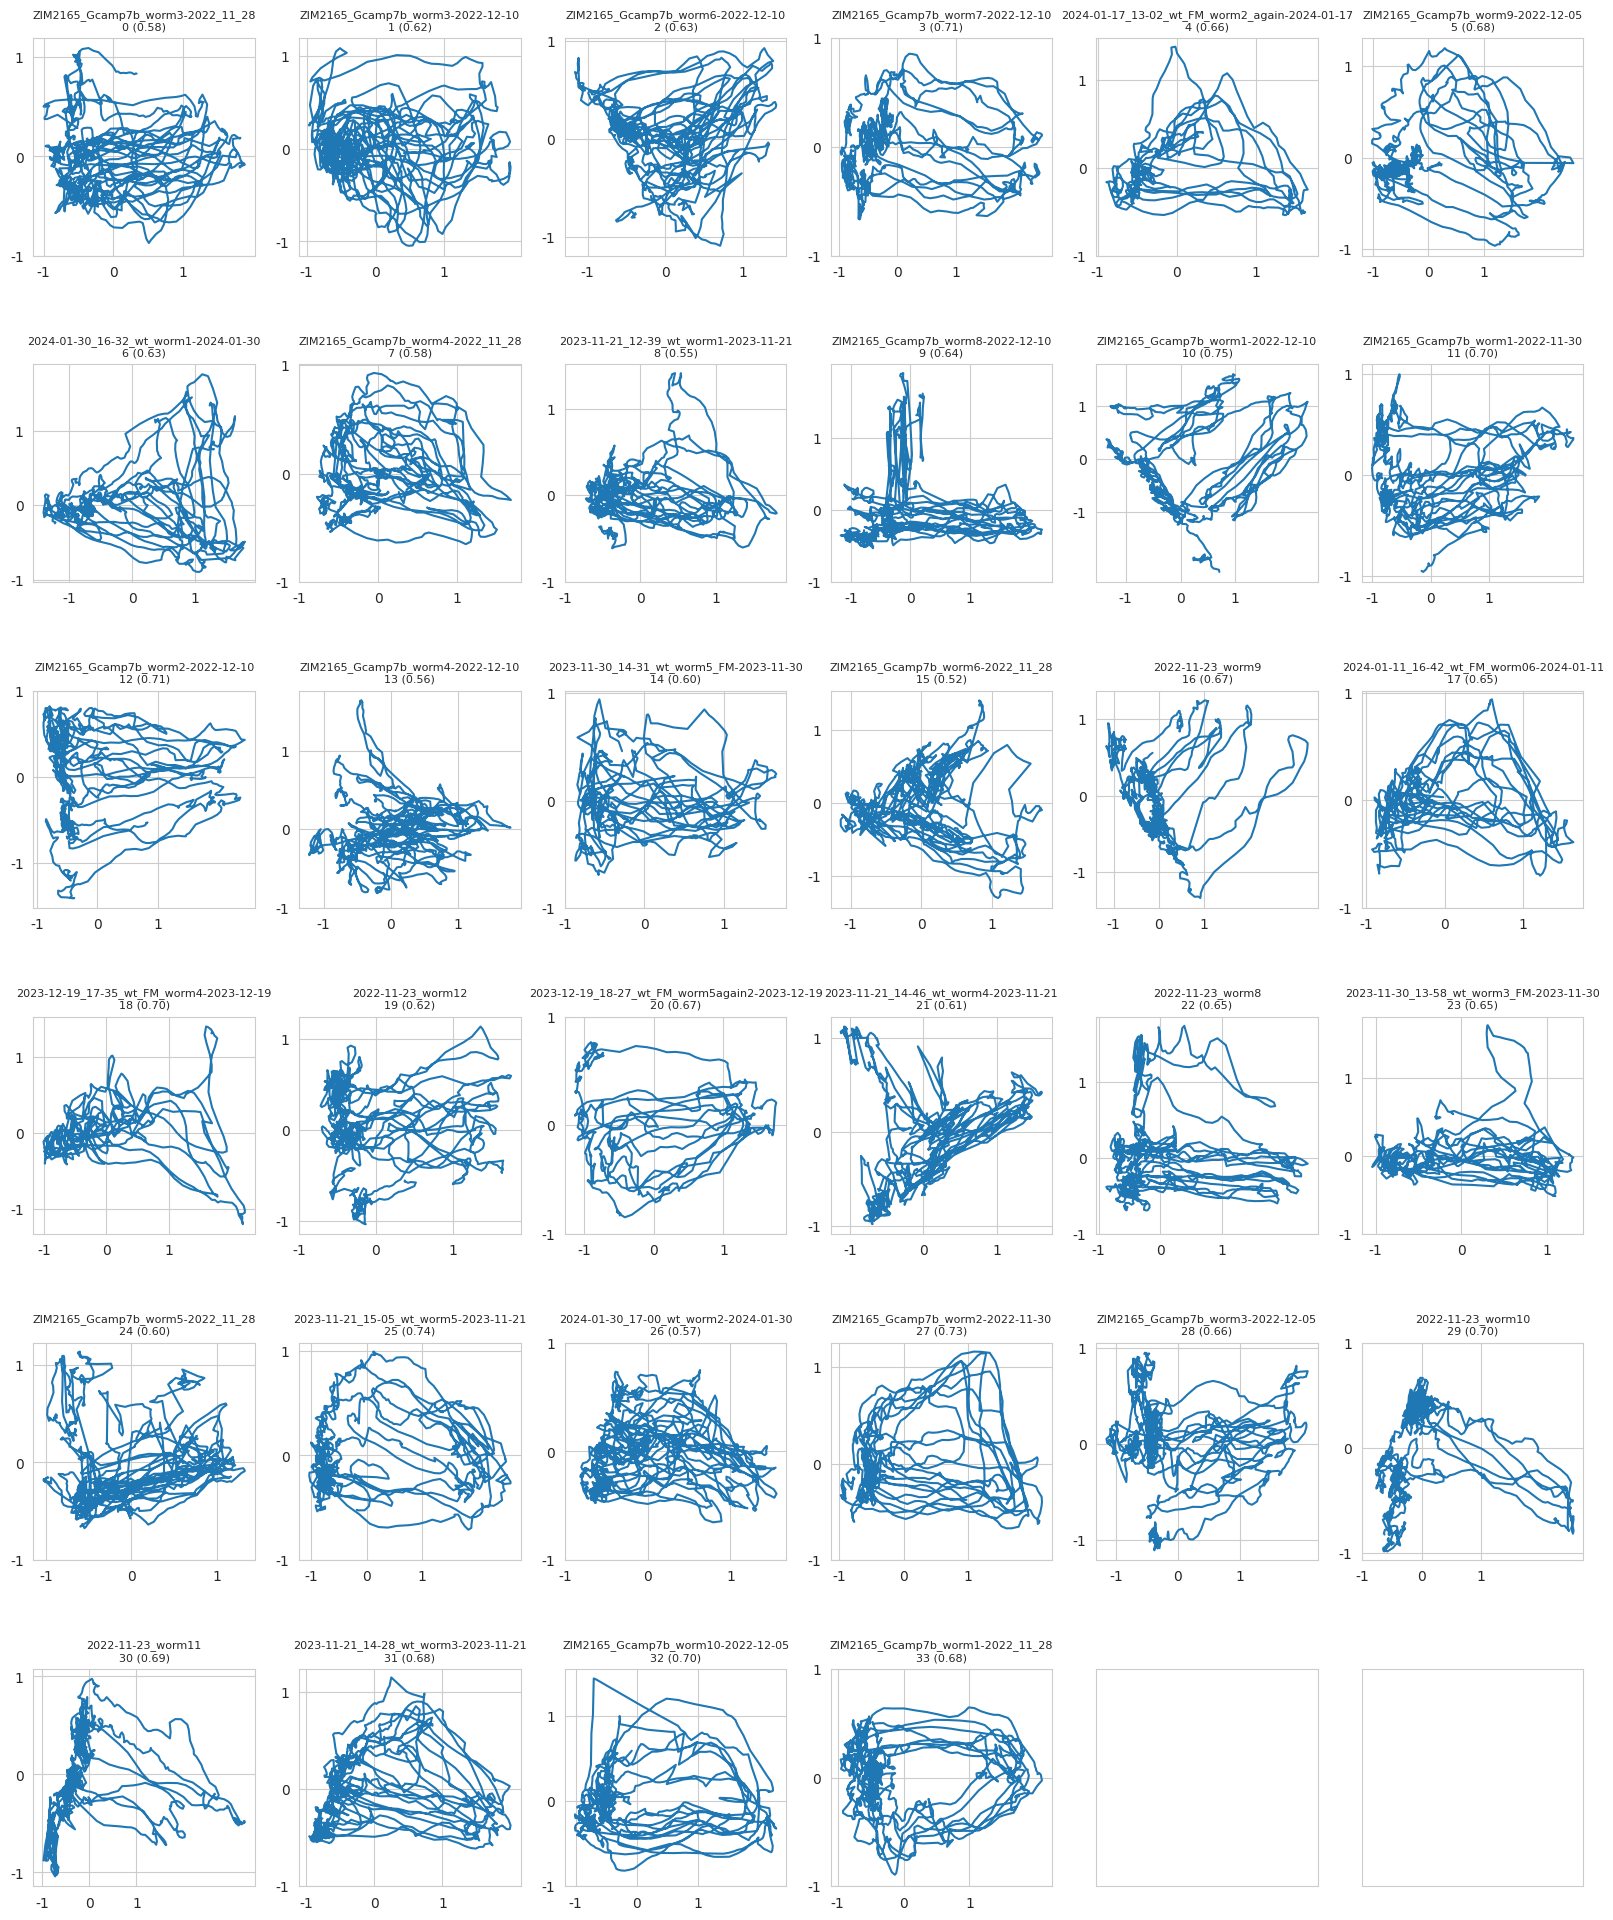

In [4]:
traces_reduced = list()
vars_explained = list()
for trace, ds in zip(traces, discrete_states):

	pca = PCA(n_components=5)
	trace_reduced = pca.fit_transform(trace)
	trace_reconstructed = pca.inverse_transform(trace_reduced)
	traces_reduced.append(trace_reduced)

	vars_explained.append(pca.explained_variance_ratio_)


n_plots = 36
dim = math.ceil(math.sqrt(n_plots))
fig, axes = plt.subplots(dim, dim, figsize=(20, 24))
for i in range(n_plots):
	axes[i // dim, i % dim].set_xticklabels([])
	axes[i // dim, i % dim].set_yticklabels([])
	axes[i // dim, i % dim].grid(False)

scale = [-1, 0, 1]
for i, signal in enumerate(traces_reduced):
	axes[i // dim, i % dim].plot(signal[:, 0], signal[:, 1])
	axes[i // dim, i % dim].set_xticks(scale)
	axes[i // dim, i % dim].set_xticklabels(scale)
	axes[i // dim, i % dim].set_yticks(scale)
	axes[i // dim, i % dim].set_yticklabels(scale)
	axes[i // dim, i % dim].grid(True)
	axes[i // dim, i % dim].set_title(f'{filenames[i][:-14]}\n{i} ({sum(vars_explained[i]):.2f})', fontsize=8)

plt.subplots_adjust(hspace=0.5)
print(np.array([sum(vars) for vars in vars_explained]).mean())

# STUFF

In [5]:
ids_chosen = [3, 10, 11, 12, 18, 25, 27, 32]
signals_reduced_chosen = [traces_reduced[i] for i in ids_chosen]

Text(0.5, 1.0, 'mean pca')

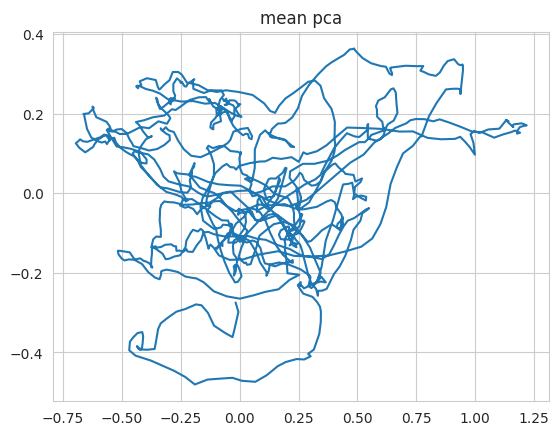

In [6]:
signals_reduced_chosen_pp = list()
for signal in signals_reduced_chosen:
	if len(signal) > 1167:
		signals_reduced_chosen_pp.append(signal[:1167])
	if len(signal) == 1166:
		signals_reduced_chosen_pp.append(signal + np.empty(signal[0].shape))
	if len(signal) < 1166:
		continue

mean = np.mean(np.array(signals_reduced_chosen_pp), axis=0)
plt.plot(mean[:, 0], mean[:, 1])
plt.title('mean pca')

In [7]:
signals_chosen = [traces[i] for i in ids_chosen]

In [8]:
min_neurons = min([array.shape[1] for array in signals_chosen])
signals_chosen_concat = np.empty((0, min_neurons))
for signal in signals_chosen:
	signals_chosen_concat = np.concatenate([signals_chosen_concat, signal[:, :min_neurons]])

InvalidIndexError: (slice(None, None, None), slice(None, 110, None))

Text(0.5, 1.0, 'concat pca')

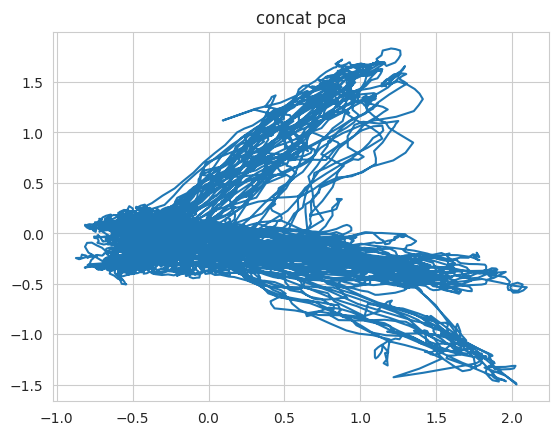

In [24]:
pca_all = PCA(n_components=2)
signals_chosen_concat_reduced = pca_all.fit_transform(signals_chosen_concat)
plt.plot(signals_chosen_concat_reduced[:, 0], signals_chosen_concat_reduced[:, 1])
plt.title('concat pca')

Text(0.5, 1.0, 'scaled concat pca')

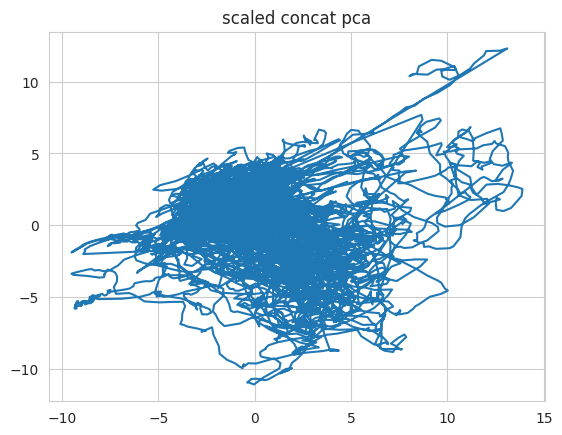

In [25]:
scaler = StandardScaler()
signals_chosen_concat_scaled = scaler.fit_transform(signals_chosen_concat)
pca_all = PCA(n_components=2)
signals_chosen_concat_scaled_reduced = pca_all.fit_transform(signals_chosen_concat_scaled)
plt.plot(signals_chosen_concat_scaled_reduced[:, 0], signals_chosen_concat_scaled_reduced[:, 1])
plt.title('scaled concat pca')